# **TikTok Project**
**Course 4 - Regression Analysis: Simplify complex data relationships**

In [1]:
import numpy as np
import pandas as pd
import platform
import statsmodels
print('Python version: ', platform.python_version())
print('numpy version: ', np.__version__)
print('pandas version: ', pd.__version__)
print('statsmodels version: ', statsmodels.__version__)

Python version:  3.11.4
numpy version:  1.24.4
pandas version:  2.0.3
statsmodels version:  0.14.0


You are a data professional at TikTok. The data team is working towards building a machine learning model that can be used to determine whether a video contains a claim or whether it offers an opinion. With a successful prediction model, TikTok can reduce the backlog of user reports and prioritize them more efficiently.

The team is getting closer to completing the project, having completed an initial plan of action, initial Python coding work, EDA, and hypothesis testing.

The TikTok team has reviewed the results of the hypothesis testing. TikTok’s Operations Lead, Maika Abadi, is interested in how different variables are associated with whether a user is verified. Earlier, the data team observed that if a user is verified, they are much more likely to post opinions. Now, the data team has decided to explore how to predict verified status to help them understand how video characteristics relate to verified users. Therefore, you have been asked to conduct a logistic regression using verified status as the outcome variable. The results may be used to inform the final model related to predicting whether a video is a claim vs an opinion.

A notebook was structured and prepared to help you in this project. Please complete the following questions.

# **Course 4 End-of-course project: Regression modeling**


In this activity, you will build a logistic regression model in Python. As you have learned, logistic regression helps you estimate the probability of an outcome. For data science professionals, this is a useful skill because it allows you to consider more than one variable against the variable you're measuring against. This opens the door for much more thorough and flexible analysis to be completed.

<br/>

**The purpose** of this project is to demostrate knowledge of EDA and regression models.

**The goal** is to build a logistic regression model and evaluate the model.
<br/>
*This activity has three parts:*

**Part 1:** EDA & Checking Model Assumptions
* What are some purposes of EDA before constructing a logistic regression model?

**Part 2:** Model Building and Evaluation
* What resources do you find yourself using as you complete this stage?

**Part 3:** Interpreting Model Results

* What key insights emerged from your model(s)?

* What business recommendations do you propose based on the models built?

Follow the instructions and answer the question below to complete the activity. Then, you will complete an executive summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work.


# **Build a regression model**

<img src="images/Pace.png" width="100" height="100" align=left>

# **PACE stages**

Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## **PACE: Plan**
Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

### **Task 1. Imports and loading**
Import the data and packages that you've learned are needed for building regression models.

In [60]:
# Import packages for data manipulation
import pandas as pd
import numpy as np


# Import packages for data visualization
import seaborn as sns
import matplotlib.pyplot as plt


# Import packages for data preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import resample


# Import packages for data modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


Load the TikTok dataset.

**Note:** As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [61]:
# Load dataset into dataframe
data = pd.read_csv("tiktok_dataset.csv")

<img src="images/Analyze.png" width="100" height="100" align=left>

## **PACE: Analyze**

Consider the questions in your PACE Strategy Document to reflect on the Analyze stage.

In this stage, consider the following question where applicable to complete your code response:

* What are some purposes of EDA before constructing a logistic regression model?


- Clean data errors or extreme values that can distort model coefficients.
- Guide feature selection and transformations to better meet model assumptions.
- Check the distribution of the target variable to see if resampling or special handling is needed.
- Ensure independent variables aren't too highly correlated with each other, which can destabilize the model.

### **Task 2a. Explore data with EDA**

Analyze the data and check for and handle missing values and duplicates.

Inspect the first five rows of the dataframe.

In [62]:
# Display first few rows
data.head()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Get the number of rows and columns in the dataset.

In [63]:
# Get number of rows and columns
data.shape


(19382, 12)

Get the data types of the columns.

In [64]:
# Get data types of columns
data.dtypes


#                             int64
claim_status                 object
video_id                      int64
video_duration_sec            int64
video_transcription_text     object
verified_status              object
author_ban_status            object
video_view_count            float64
video_like_count            float64
video_share_count           float64
video_download_count        float64
video_comment_count         float64
dtype: object

Get basic information about the dataset.

In [65]:
# Get basic information
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


Generate basic descriptive statistics about the dataset.

In [66]:
# Generate basic descriptive stats
data.describe()


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


Check for and handle missing values.

In [67]:
# Check for missing values
data.isna().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [68]:
# Drop rows with missing values
data = data.dropna(axis=0)

In [69]:
# Display first few rows after handling missing values
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Check for and handle duplicates.

In [70]:
# Check for duplicates
data.duplicated().sum()

0

Check for and handle outliers.

Text(0.5, 0, 'Video duration in segs')

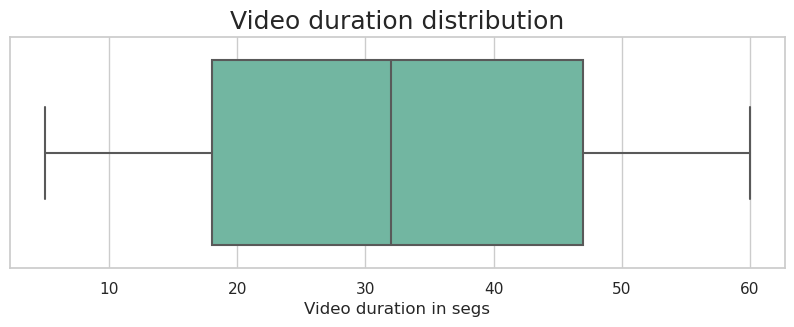

In [71]:
# Create a boxplot to visualize distribution of `video_duration_sec`
plt.figure(figsize=(10,3))
sns.set(style='whitegrid', palette='Set2')
sns.boxplot(data=data, x='video_duration_sec', fliersize=1)
plt.title('Video duration distribution', fontsize=18)
plt.xlabel('Video duration in segs')

Text(0.5, 0, 'Quantity of views per video')

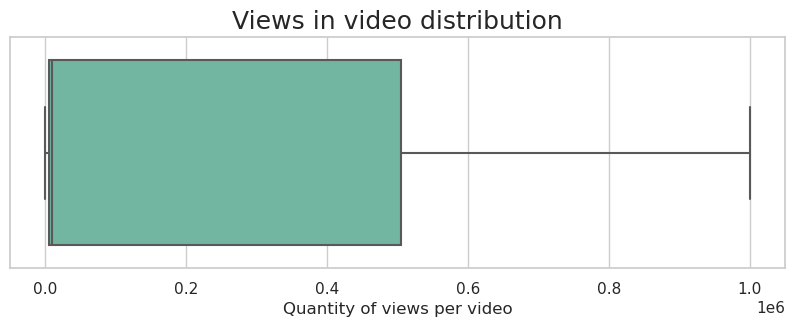

In [72]:
# Create a boxplot to visualize distribution of `video_view_count`
plt.figure(figsize=(10,3))
sns.boxplot(data=data, x='video_view_count', fliersize=1)
plt.title('Views in video distribution', fontsize=18)
plt.xlabel('Quantity of views per video')

Text(0.5, 0, 'Likes in video')

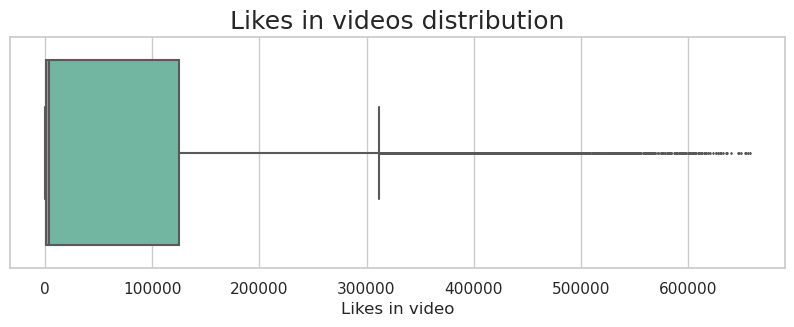

In [73]:
# Create a boxplot to visualize distribution of `video_like_count`
plt.figure(figsize=(10,3))
sns.boxplot(data=data, x='video_like_count', fliersize=1)
plt.title('Likes in videos distribution', fontsize=18)
plt.xlabel('Likes in video')

Text(0.5, 0, 'Comments in video')

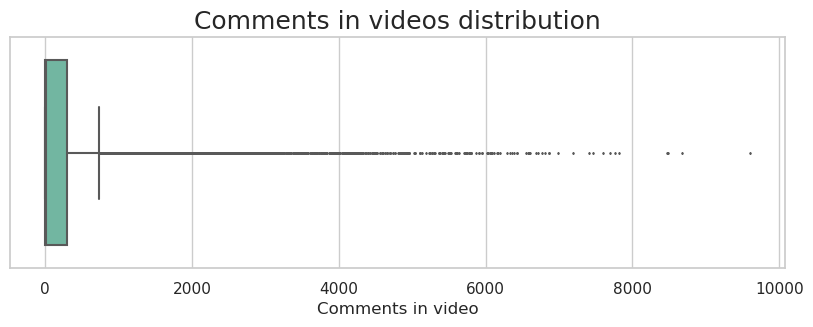

In [74]:
# Create a boxplot to visualize distribution of `video_comment_count`
plt.figure(figsize=(10,3))
sns.boxplot(data=data, x='video_comment_count', fliersize=1)
plt.title('Comments in videos distribution', fontsize=18)
plt.xlabel('Comments in video')

In [75]:
# Check for and handle outliers for video_like_count
q1 = data['video_like_count'].quantile(0.25)
q3 = data['video_like_count'].quantile(0.75)
IQR = q3 - q1

upper_limit = q3 + 1.5*IQR

data['video_like_count'] = data['video_like_count'].clip(upper=upper_limit)

Text(0.5, 0, 'Likes in video')

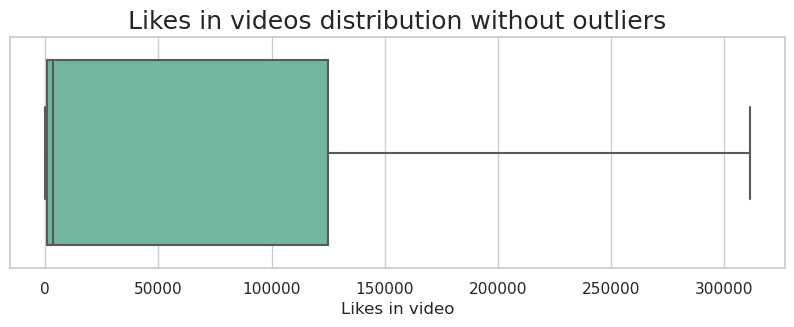

In [76]:
plt.figure(figsize=(10,3))
sns.boxplot(data=data, x='video_like_count', fliersize=1)
plt.title('Likes in videos distribution without outliers', fontsize=18)
plt.xlabel('Likes in video')

In [77]:
# Check for and handle outliers for video_comment_count`
q1 = data['video_comment_count'].quantile(0.25)
q3 = data['video_comment_count'].quantile(0.75)
IQR = q3 - q1

upper_limit = q3 + 1.5*IQR

data['video_comment_count'] = data['video_comment_count'].clip(upper=upper_limit)

Text(0.5, 0, 'Comments in video')

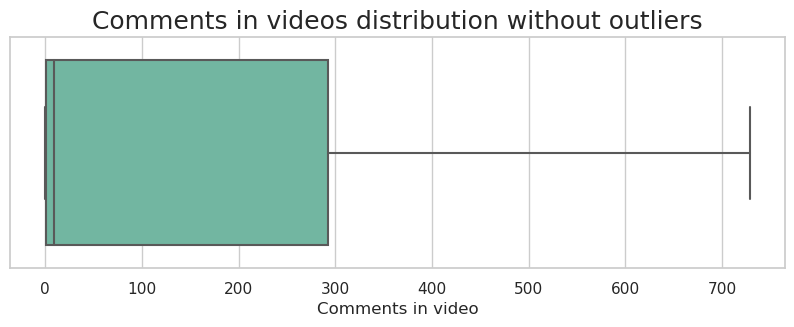

In [78]:
plt.figure(figsize=(10,3))
sns.boxplot(data=data, x='video_comment_count', fliersize=1)
plt.title('Comments in videos distribution without outliers', fontsize=18)
plt.xlabel('Comments in video')

Check class balance of the target variable. Remember, the goal is to predict whether the user of a given post is verified or unverified.

In [79]:
# Check class balance
print(data['verified_status'].value_counts())
data['verified_status'].value_counts(normalize=True)*100

verified_status
not verified    17884
verified         1200
Name: count, dtype: int64


verified_status
not verified    93.71201
verified         6.28799
Name: proportion, dtype: float64

Approximately 93.7% of the dataset represents videos posted by unverified accounts and 6.3% represents videos posted by verified accounts. So the outcome variable is not very balanced.

Use resampling to create class balance in the outcome variable, if needed.

In [80]:
# Use resampling to create class balance in the outcome variable, if needed

# Identify data points from majority and minority classes
data_majority = data[data['verified_status'] == 'not verified']
data_minority = data[data['verified_status'] == 'verified']

# Upsample the minority class (which is "verified")
minority_upsampled = resample(
    data_minority,
    replace=True, 
    n_samples=len(data_majority),  
    random_state=42, 
)

# Combine majority class with upsampled minority class
data_resampled = pd.concat([data_majority, minority_upsampled])

# Display new class counts
data_resampled['verified_status'].value_counts()

verified_status
not verified    17884
verified        17884
Name: count, dtype: int64

Get the average `video_transcription_text` length for videos posted by verified accounts and the average `video_transcription_text` length for videos posted by unverified accounts.



In [81]:
# Get the average `video_transcription_text` length for claims and the average `video_transcription_text` length for opinions
print('Verified mean length text: ', data_resampled[data_resampled['verified_status'] == 'verified']['video_transcription_text'].str.len().mean())
print('Unverified mean length text: ', data_resampled[data_resampled['verified_status'] == 'not verified']['video_transcription_text'].str.len().mean())

Verified mean length text:  84.56301722209797
Unverified mean length text:  89.40114068441065


Extract the length of each `video_transcription_text` and add this as a column to the dataframe, so that it can be used as a potential feature in the model.

In [82]:
# Extract the length of each `video_transcription_text` and add this as a column to the dataframe
data_resampled['length_transcript'] = data_resampled['video_transcription_text'].str.len()

In [83]:
# Display first few rows of dataframe after adding new column
data_resampled.head()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,length_transcript
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0,97
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0,107
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0,137
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0,131
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0,128


Visualize the distribution of `video_transcription_text` length for videos posted by verified accounts and videos posted by unverified accounts.

Text(0.5, 0, 'Length of transcript')

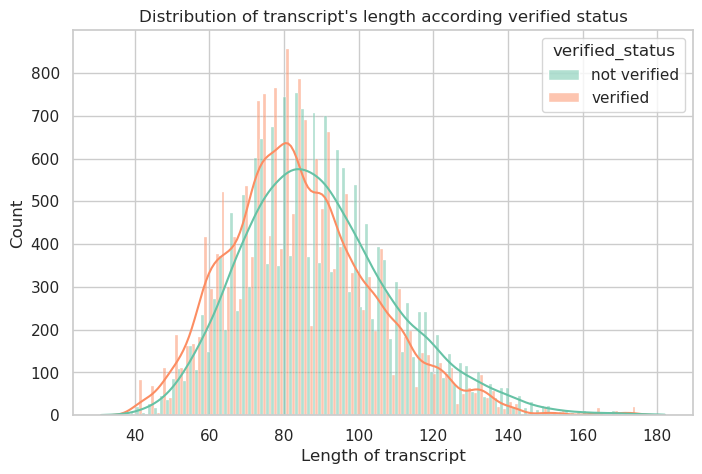

In [84]:
# Visualize the distribution of `video_transcription_text` length for videos posted by verified accounts and videos posted by unverified accounts
# Create two histograms in one plot
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data_resampled,
    x='length_transcript',
    hue='verified_status',
    multiple='dodge',  
    kde=True,  
)
plt.title("Distribution of transcript's length according verified status")
plt.xlabel('Length of transcript')

### **Task 2b. Examine correlations**

Next, code a correlation matrix to help determine most correlated variables.

In [86]:
# Code a correlation matrix to help determine most correlated variables
corr_matrix = data_resampled.corr(numeric_only=True)
corr_matrix


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,length_transcript
#,1.000000,-0.001369,-0.011800,-0.698969,-0.626105,-0.503634,-0.489758,-0.610763,-0.196817
video_id,-0.001369,1.000000,0.013938,0.001607,0.004534,0.009136,0.006814,0.010564,-0.007634
video_duration_sec,-0.011800,0.013938,1.000000,0.013892,0.004028,0.001944,0.006930,-0.000080,-0.005043
video_view_count,-0.698969,0.001607,0.013892,1.000000,0.855343,0.710466,0.691557,0.747564,0.246867
video_like_count,-0.626105,0.004534,0.004028,0.855343,1.000000,0.832361,0.806369,0.816416,0.217852
video_share_count,-0.503634,0.009136,0.001944,0.710466,0.832361,1.000000,0.709738,0.671601,0.176362
video_download_count,-0.489758,0.006814,0.006930,0.691557,0.806369,0.709738,1.000000,0.794524,0.175287
video_comment_count,-0.610763,0.010564,-0.000080,0.747564,0.816416,0.671601,0.794524,1.000000,0.217179
length_transcript,-0.196817,-0.007634,-0.005043,0.246867,0.217852,0.176362,0.175287,0.217179,1.000000


Visualize a correlation heatmap of the data.

Text(0.5, 1.0, "Variable's Correlation Matrix")

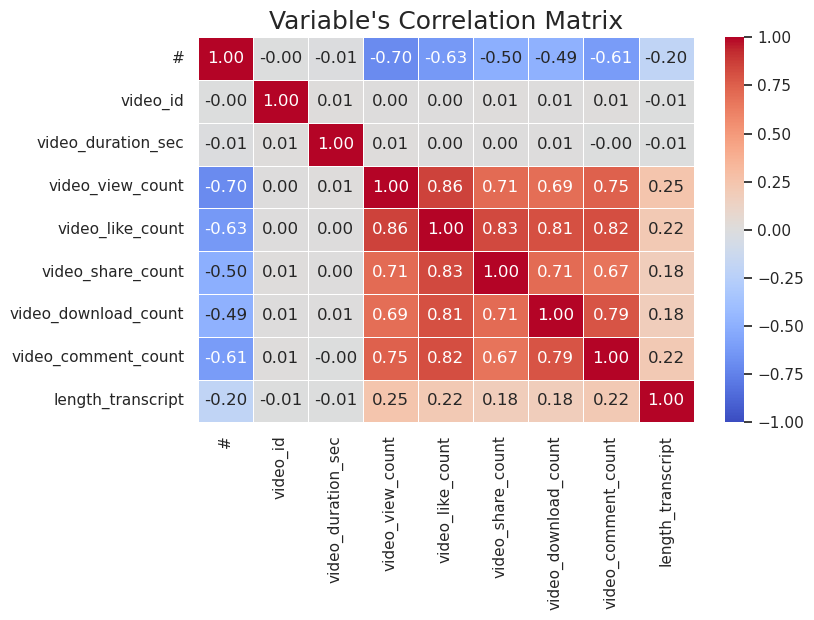

In [87]:
# Create a heatmap to visualize how correlated variables are
plt.figure(figsize=(8,5))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, fmt='.2f')
plt.title("Variable's Correlation Matrix", fontsize=18)


One of the model assumptions for logistic regression is no severe multicollinearity among the features. Take this into consideration as you examine the heatmap and choose which features to proceed with.

**Question:** What variables are shown to be correlated in the heatmap?
- Engagement variables exhibit very strong correlations with one another. video_view_count and video_like_count share the highest correlation, followed closely by strong associations with video_share_count, video_comment_count, and video_download_count, indicating severe multicollinearity.
- These engagement metrics show low correlation with length transcript and near-zero correlation with structural variables like video_id or video_duration_sec.
- To effectively mitigate multicollinearity in the logistic regression model, it is recommended to include only one of the two that have that strong correlation.

<img src="images/Construct.png" width="100" height="100" align=left>

## **PACE: Construct**

After analysis and deriving variables with close relationships, it is time to begin constructing the model. Consider the questions in your PACE Strategy Document to reflect on the Construct stage.

### **Task 3a. Select variables**

Set your Y and X variables.

Select the outcome variable.

In [88]:
# Select outcome variable
y = data_resampled["verified_status"]


Select the features.

In [89]:
# Select features
X = data_resampled[["video_duration_sec", "claim_status", "author_ban_status", "video_view_count", "video_share_count", "video_download_count", "video_comment_count"]]

# Display first few rows of features dataframe
X.head()


,video_duration_sec,claim_status,author_ban_status,video_view_count,video_share_count,video_download_count,video_comment_count
0,59,claim,under review,343296.0,241.0,1.0,0.0
1,32,claim,active,140877.0,19034.0,1161.0,684.0
2,31,claim,active,902185.0,2858.0,833.0,329.0
3,25,claim,active,437506.0,34812.0,1234.0,584.0
4,19,claim,active,56167.0,4110.0,547.0,152.0


### **Task 3b. Train-test split**

Split the data into training and testing sets.

In [90]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

Confirm that the dimensions of the training and testing sets are in alignment.

In [91]:
# Get shape of each training and testing set
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((25037, 7), (10731, 7), (25037,), (10731,))

### **Task 3c. Encode variables**

Check the data types of the features.

In [92]:
# Check data types
X_train.dtypes


video_duration_sec        int64
claim_status             object
author_ban_status        object
video_view_count        float64
video_share_count       float64
video_download_count    float64
video_comment_count     float64
dtype: object

In [93]:
# Get unique values in `claim_status`
X_train['claim_status'].unique()

array(['opinion', 'claim'], dtype=object)

In [94]:
# Get unique values in `author_ban_status`
X_train['author_ban_status'].unique()

array(['active', 'banned', 'under review'], dtype=object)

As shown above, the `claim_status` and `author_ban_status` features are each of data type `object` currently. In order to work with the implementations of models through `sklearn`, these categorical features will need to be made numeric. One way to do this is through one-hot encoding.

Encode categorical features in the training set using an appropriate method.

In [95]:
# Select the training features that needs to be encoded
X_train_categorical = X_train[['claim_status', 'author_ban_status']]

# Display first few rows
X_train_categorical.head()

,claim_status,author_ban_status
14981,opinion,active
16314,opinion,active
18140,opinion,active
93,claim,banned
11101,opinion,active


In [96]:
# Set up an encoder for one-hot encoding the categorical features
X_encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

In [97]:
# Fit and transform the training features using the encoder
X_train_encoded = X_encoder.fit_transform(X_train_categorical)

In [98]:
# Get feature names from encoder
X_encoder.get_feature_names_out()

array(['claim_status_opinion', 'author_ban_status_banned',
       'author_ban_status_under review'], dtype=object)

In [99]:
# Display first few rows of encoded training features
X_train_encoded

array([[1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       ...,
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.]])

In [100]:
# Place encoded training features (which is currently an array) into a dataframe
X_train_encoded_df = pd.DataFrame(
    X_train_encoded, columns=X_encoder.get_feature_names_out(), index=X_train.index
)

# Display first few rows
X_train_encoded_df.head()

,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
14981,1.0,0.0,0.0
16314,1.0,0.0,0.0
18140,1.0,0.0,0.0
93,0.0,1.0,0.0
11101,1.0,0.0,0.0


In [101]:
# Display first few rows of `X_train` with `claim_status` and `author_ban_status` columns dropped (since these features are being transformed to numeric)
X_train.drop(columns = ['claim_status', 'author_ban_status']).head()

,video_duration_sec,video_view_count,video_share_count,video_download_count,video_comment_count
14981,58,1235.0,114.0,2.0,1.0
16314,11,5510.0,252.0,1.0,0.0
18140,38,7496.0,542.0,19.0,5.0
93,37,436875.0,41775.0,4663.0,728.5
11101,30,955.0,3.0,0.0,0.0


In [102]:
# Concatenate `X_train` and `X_train_encoded_df` to form the final dataframe for training data (`X_train_final`)
# Note: Using `.reset_index(drop=True)` to reset the index in X_train after dropping `claim_status` and `author_ban_status`,
# so that the indices align with those in `X_train_encoded_df` and `count_df`
X_train_final = pd.concat(
    [
        X_train.drop(
            columns=['claim_status', 'author_ban_status']
        ).reset_index(drop=True),
        X_train_encoded_df.reset_index(drop=True),
    ],
    axis=1,
)

# Display first few rows
X_train_final.head()

,video_duration_sec,video_view_count,video_share_count,video_download_count,video_comment_count,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,58,1235.0,114.0,2.0,1.0,1.0,0.0,0.0
1,11,5510.0,252.0,1.0,0.0,1.0,0.0,0.0
2,38,7496.0,542.0,19.0,5.0,1.0,0.0,0.0
3,37,436875.0,41775.0,4663.0,728.5,0.0,1.0,0.0
4,30,955.0,3.0,0.0,0.0,1.0,0.0,0.0


Check the data type of the outcome variable.

In [103]:
# Check data type of outcome variable
y_train.dtype


dtype('O')

In [104]:
# Get unique values of outcome variable
y_train.unique()


array(['verified', 'not verified'], dtype=object)

A shown above, the outcome variable is of data type `object` currently. One-hot encoding can be used to make this variable numeric.

Encode categorical values of the outcome variable the training set using an appropriate method.

In [105]:
# Set up an encoder for one-hot encoding the categorical outcome variable
y_encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

In [106]:
# Encode the training outcome variable
# Notes:
#   - Adjusting the shape of `y_train` before passing into `.fit_transform()`, since it takes in 2D array
#   - Using `.ravel()` to flatten the array returned by `.fit_transform()`, so that it can be used later to train the model
y_train_encoded = y_encoder.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

# Display the encoded training outcome variable
y_train_encoded


array([1., 1., 0., ..., 0., 0., 0.])

### **Task 3d. Model building**

Construct a model and fit it to the training set.

In [107]:
# Construct a logistic regression model and fit it to the training set
clf = LogisticRegression(random_state=42).fit(X_train_final,y_train_encoded)


<img src="images/Execute.png" width="100" height="100" align=left>

## **PACE: Execute**

Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### **Taks 4a. Results and evaluation**

Evaluate your model.

Encode categorical features in the testing set using an appropriate method.

In [108]:
# Select the testing features that needs to be encoded
X_test_categorical = X_test[['claim_status', 'author_ban_status']]

# Display first few rows
X_test_categorical

,claim_status,author_ban_status
15439,opinion,active
1266,claim,under review
12194,opinion,under review
17408,opinion,banned
14057,opinion,banned
...,...,...
17830,opinion,active
10409,opinion,active
14946,opinion,active
1626,claim,active


In [109]:
# Transform the testing features using the encoder
X_test_encoded = X_encoder.fit_transform(X_test_categorical)

# Display first few rows of encoded testing features
X_test_encoded

array([[1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 1.],
       ...,
       [1., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [110]:
# Place encoded testing features (which is currently an array) into a dataframe
X_test_encoded_df = pd.DataFrame(data=X_test_encoded, columns = X_encoder.get_feature_names_out())

# Display first few rows
X_test_encoded_df.head()


,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,1.0,0.0,1.0
3,1.0,1.0,0.0
4,1.0,1.0,0.0


In [111]:
# Display first few rows of `X_test` with `claim_status` and `author_ban_status` columns dropped (since these features are being transformed to numeric)
X_test.drop(columns = ['claim_status', 'author_ban_status']).head()


,video_duration_sec,video_view_count,video_share_count,video_download_count,video_comment_count
15439,14,1580.0,49.0,12.0,1.0
1266,43,862507.0,86137.0,3206.0,265.0
12194,52,449.0,20.0,0.0,0.0
17408,17,4458.0,111.0,6.0,2.0
14057,8,9877.0,65.0,5.0,1.0


In [112]:
# Concatenate `X_test` and `X_test_encoded_df` to form the final dataframe for training data (`X_test_final`)
# Note: Using `.reset_index(drop=True)` to reset the index in X_test after dropping `claim_status`, and `author_ban_status`,
# so that the indices align with those in `X_test_encoded_df` and `test_count_df`
X_test_final = pd.concat(
    [
        X_test.drop(
            columns=['claim_status', 'author_ban_status']
        ).reset_index(drop=True),
        X_test_encoded_df.reset_index(drop=True),
    ],
    axis=1,
)

# Display first few rows
X_test_final.head()

,video_duration_sec,video_view_count,video_share_count,video_download_count,video_comment_count,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,14,1580.0,49.0,12.0,1.0,1.0,0.0,0.0
1,43,862507.0,86137.0,3206.0,265.0,0.0,0.0,1.0
2,52,449.0,20.0,0.0,0.0,1.0,0.0,1.0
3,17,4458.0,111.0,6.0,2.0,1.0,1.0,0.0
4,8,9877.0,65.0,5.0,1.0,1.0,1.0,0.0


Test the logistic regression model. Use the model to make predictions on the encoded testing set.

In [113]:
# Use the logistic regression model to get predictions on the encoded testing set
y_pred = clf.predict(X_test_final)


Display the predictions on the encoded testing set.

In [114]:
# Display the predictions on the encoded testing set
y_pred


array([1., 0., 1., ..., 1., 0., 0.])

Display the true labels of the testing set.

In [115]:
# Display the true labels of the testing set
y_test


15439        verified
1266     not verified
12194        verified
17408        verified
14057        verified
             ...     
17830    not verified
10409        verified
14946        verified
1626     not verified
7849     not verified
Name: verified_status, Length: 10731, dtype: object

Encode the true labels of the testing set so it can be compared to the predictions.

In [116]:
# Encode the testing outcome variable
# Notes:
#   - Adjusting the shape of `y_test` before passing into `.transform()`, since it takes in 2D array
#   - Using `.ravel()` to flatten the array returned by `.transform()`, so that it can be used later to compare with predictions
y_test_encoded = y_encoder.fit_transform(
    y_test.values.reshape(-1, 1)
).ravel()

# Display the encoded training outcome variable
y_test_encoded


array([1., 0., 1., ..., 1., 0., 0.])

Confirm again that the dimensions of the training and testing sets are in alignment since additional features were added.

In [119]:
# Get shape of each training and testing set
X_train_final.shape, y_train.shape, X_test_final.shape, y_test_encoded.shape


((25037, 8), (25037,), (10731, 8), (10731,))

### **Task 4b. Visualize model results**

Create a confusion matrix to visualize the results of the logistic regression model.

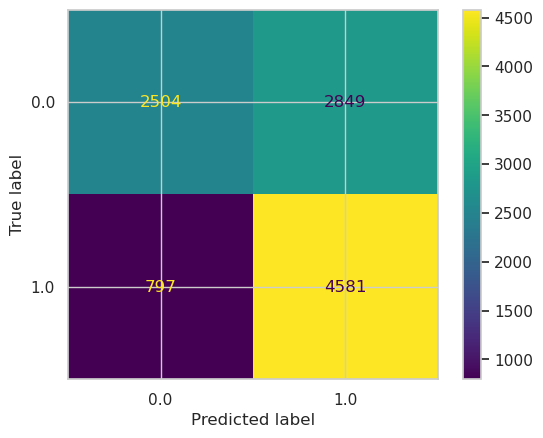

In [120]:
# Compute values for confusion matrix
cm = confusion_matrix(y_test_encoded, y_pred, labels=clf.classes_)

# Create display of confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels = clf.classes_)

# Plot confusion matrix
disp.plot()

# Display plot
plt.show()

Create a classification report that includes precision, recall, f1-score, and accuracy metrics to evaluate the performance of the logistic regression model.

In [121]:
# Create a classification report
print(classification_report(y_test_encoded, y_pred))


              precision    recall  f1-score   support

         0.0       0.76      0.47      0.58      5353
         1.0       0.62      0.85      0.72      5378

    accuracy                           0.66     10731
   macro avg       0.69      0.66      0.65     10731
weighted avg       0.69      0.66      0.65     10731



### **Task 4c. Interpret model coefficients**

In [126]:
# Get the feature names from the model and the model coefficients (which represent log-odds ratios)
# Place into a DataFrame for readability
df_coefficients = pd.DataFrame(
    {"Feature":clf.feature_names_in_,
     "Coefficient":clf.coef_[0]}
)

df_coefficients.sort_values(by = 'Coefficient')

,Feature,Coefficient
4,video_comment_count,-0.000608
3,video_download_count,-0.000041
6,author_ban_status_banned,-0.000013
7,author_ban_status_under review,-0.000005
1,video_view_count,-0.000002
2,video_share_count,0.000007
5,claim_status_opinion,0.000384
0,video_duration_sec,0.008870


### **Task 4d. Conclusion**

1. What are the key takeaways from this project?

2. What results can be presented from this project?

**Takeaways**
* **Importance of EDA:** Exploratory Data Analysis (EDA) is essential to understand the dataset, check for null and duplicate values, and detect outliers that could impact model performance. It also helps select the features to be used after checking correlations and assumptions, and verifying whether the target variable suffers from class imbalance.
* **Preventing Data Leakage:** Categorical encoding must be performed after splitting the data into training and testing sets to prevent data leakage and pipeline errors. Additionally, when concatenating the encoded features back into the working dataset, both DataFrames' indices must be reset to avoid row misalignment.
* **Proper Use of OneHotEncoder:** Separate encoder instances should be used for the features (X) and the target variable (y). For the features (X), the exact same encoder instance (fitted exclusively on the training data) must be used for both training and testing datasets to properly apply the learned categorical mapping.
* **Generating Predictions:** Target variable predictions are generated using the model's .predict() method by passing the properly prepared test features (X_test), which returns a NumPy array.
* **Model Evaluation:** The test target labels must also be encoded consistently so they can be accurately compared against the model's predictions using evaluation tools such as a confusion matrix or a classification report.

**Results**

**1. Correlation & Multicollinearity Analysis**
* **Engagement multicollinearity:** Engagement variables exhibit very strong correlations with one another. video_view_count and video_like_count share the highest correlation, followed closely by strong associations with video_share_count, video_comment_count, and video_download_count, indicating severe multicollinearity.

* **Structural independence:** These metrics show low correlation with the transcript length and near-zero correlation with structural variables like video_id or video_duration_sec.
 
**2. Classification Report & Confusion Matrix Analysis**

**Overall performance:** The model achieves an overall accuracy of 66% (0.66) on the test set consisting of 10,731 total samples.
* **Class 0.0 (Unverified Users):** It presents an acceptable precision of 76% (0.76), meaning that when the model predicts a user is unverified, it is correct most of the time. However, the recall is low at 47% (0.47), indicating that the model struggles to detect and capture all actual unverified users, resulting in many false negatives.
* **Class 1.0 (Verified Users):** It displays an excellent recall of 85% (0.85), demonstrating a high capability to identify verified accounts and avoid missing them. Its precision is 62% (0.62), reflecting that predicting this class also introduces some false positives.
  
**Performance summary:** The model exhibits a bias or higher proficiency in predicting verified users (1.0), but its performance drops notably when trying to correctly classify unverified users (0.0).
  
**3. Model Coefficients Analysis**
* **Positive coefficients (video_duration_sec and claim_status_opinion):** video_duration_sec (0.008870) and claim_status_opinion (0.000384) possess positive coefficients, indicating that longer video durations or content expressing an opinion slightly increase the probability that the author is a verified account.
* **Penalty variables (author_ban_status):** author_ban_status_banned (-0.000013) and author_ban_status_under_review (-0.000005) have negative coefficients; if an account is banned or under review, the likelihood of it being verified drops drastically.
* **Engagement metrics:** video_comment_count (-0.000608), video_download_count (-0.000041), and video_view_count (-0.000002) present negative values, suggesting that higher comment volumes, downloads, or views inversely align with the probability of belonging to a verified user, pointing more toward standard or unverified account dynamics.

**To improve model performance, the following actions are recommended:**
* **Mitigate multicollinearity:** Select only one representative feature among those exhibiting strong correlations, or apply feature engineering to combine them into a single metric.

* **Tune optimization hyperparameters:** Incorporate more robust control parameters during model creation, such as class_weight='balanced' to handle class imbalance and an appropriate max_iter value to ensure algorithm convergence.

* **Implement non-linear models:** Explore tree-based architectures (such as Random Forest or Gradient Boosting) that can capture complex relationships more effectively than linear models.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged. 